# Projet 3 — Gradient et gradient stochastique pour le SVM linéaire

1. Implantation de la méthode du (sous-)gradient et du gradient stochastique pour le SVM, d'après
   [EE 227C, Lecture 4](https://ee227c.github.io/code/lecture4.html#svm), et reproduction de ses expériences.
2. Influence de la longueur du pas et de la taille du mini-batch.
3. Reproduction, avec notre SVM, des 6 vérifications de
   [Kenneth Leung](https://github.com/kennethleungty/Logistic-Regression-Assumptions) sur **Titanic** et sur les
   données irlandaises **Irish Educational Transitions**.

In [9]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.random.seed(1337); rng = np.random.default_rng(1337)

def save(name):  # figures pour le rapport LaTeX
    if os.path.isdir('Rapport/Figures'): plt.savefig(f'Rapport/Figures/{name}.png', dpi=150, bbox_inches='tight')

## 1. SVM linéaire et méthode du sous-gradient (Berkeley)

Étiquettes $y_i\in\{-1,+1\}$. On cherche $x$ tel que $y_i\,a_i^\top x\ge 1$ (marge $1/\|x\|$), d'où l'objectif

$$f(x)=\frac1m\sum_{i=1}^m\max\{0,\,1-y_ia_i^\top x\}+\frac\alpha2\|x\|^2 .$$

$f$ est $\alpha$-fortement convexe mais **non différentiable** (perte charnière en $y_ia_i^\top x=1$). Un sous-gradient est

$$g(x)=-\frac1m\sum_{i:\,y_ia_i^\top x<1}y_ia_i+\alpha x\ \in\ \partial f(x).$$

Méthode du sous-gradient : $x_{k+1}=x_k-\eta_k g(x_k)$. Ce n'est pas une méthode de descente ; la théorie
(fonction $\alpha$-fortement convexe, sous-gradients bornés) préconise $\eta_k=1/(\alpha k)$ et la **moyenne des
itérés**. Version stochastique (type *Pegasos*) : on remplace la moyenne sur $i$ par une moyenne sur un mini-batch $B_k$.

In [10]:
def hinge_loss(z):
    return np.maximum(1. - z, 0.)

def svm_objective(A, y, x, alpha=0.05):
    return np.mean(hinge_loss(y * (A @ x))) + alpha / 2 * x @ x

def svm_subgradient(A, y, x, alpha=0.05):
    active = y * (A @ x) < 1
    return -A.T @ (y * active) / len(y) + alpha * x

def accuracy(A, y, x):
    return np.mean(y * (A @ x) > 0)

def gradient_descent(init, steps, grad, proj=lambda x: x):
    # identique à Berkeley
    xs = [init]
    for step in steps:
        xs.append(proj(xs[-1] - step * grad(xs[-1])))
    return xs

def sgd(A, y, x0, step, batch_size, epochs, alpha=0.05, seed=0):
    # Sous-gradient stochastique par mini-batch ; step : fonction k -> eta_k. Renvoie l'itéré après chaque epoch.
    gen = np.random.default_rng(seed); m = len(y); x = x0.copy(); xs = [x.copy()]; k = 0
    for _ in range(epochs):
        perm = gen.permutation(m)
        for s in range(0, m, batch_size):
            i = perm[s:s + batch_size]; k += 1
            x = x - step(k) * svm_subgradient(A[i], y[i], x, alpha)
        xs.append(x.copy())
    return xs

### 1.1 Expérience de Berkeley
Deux nuages gaussiens de moyennes $\pm0{,}1\cdot\mathbf 1$ dans $\mathbb R^{100}$ ; le classifieur optimal en population
est $x=\mathbf 1$. Remarque : le code de Berkeley somme les sous-gradients au lieu d'en faire la moyenne ; son pas
$0{,}01$ correspond donc à $\eta=10$ avec notre normalisation.

objectif : dernier itéré 0.4006 ; moyenne des itérés 0.5250


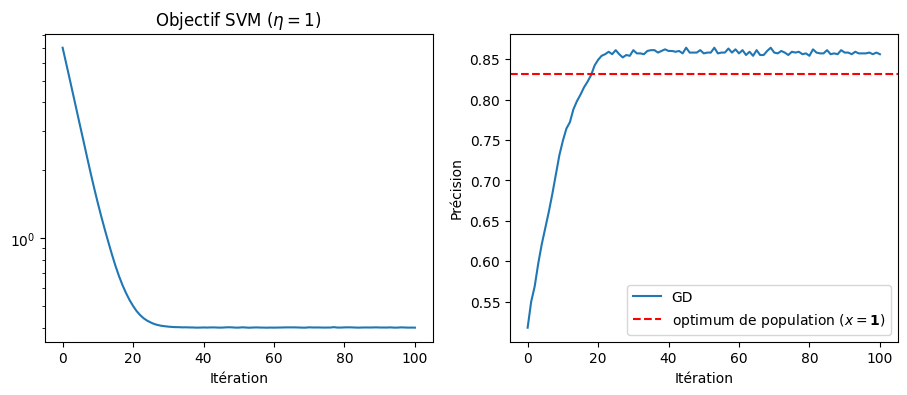

In [11]:
m, n, alpha = 1000, 100, 0.05
A = np.vstack([rng.normal(0.1, 1, (m // 2, n)), rng.normal(-0.1, 1, (m // 2, n))])
y = np.hstack([np.ones(m // 2), -np.ones(m // 2)])
x0 = rng.normal(0, 1, n)
xs = gradient_descent(x0, [1.0] * 100, lambda x: svm_subgradient(A, y, x, alpha))
x_avg = np.mean(xs, axis=0)
print(f'objectif : dernier itéré {svm_objective(A, y, xs[-1]):.4f} ; moyenne des itérés {svm_objective(A, y, x_avg):.4f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot([svm_objective(A, y, x) for x in xs]); ax[0].set_yscale('log')
ax[0].set(xlabel='Itération', title='Objectif SVM ($\\eta=1$)')
ax[1].plot([accuracy(A, y, x) for x in xs], label='GD')
ax[1].axhline(accuracy(A, y, np.ones(n)), color='r', ls='--', label='optimum de population ($x=\\mathbf{1}$)')
ax[1].set(xlabel='Itération', ylabel='Précision'); ax[1].legend(); save('berkeley_svm'); plt.show()

## 2. Longueur du pas et taille du mini-batch

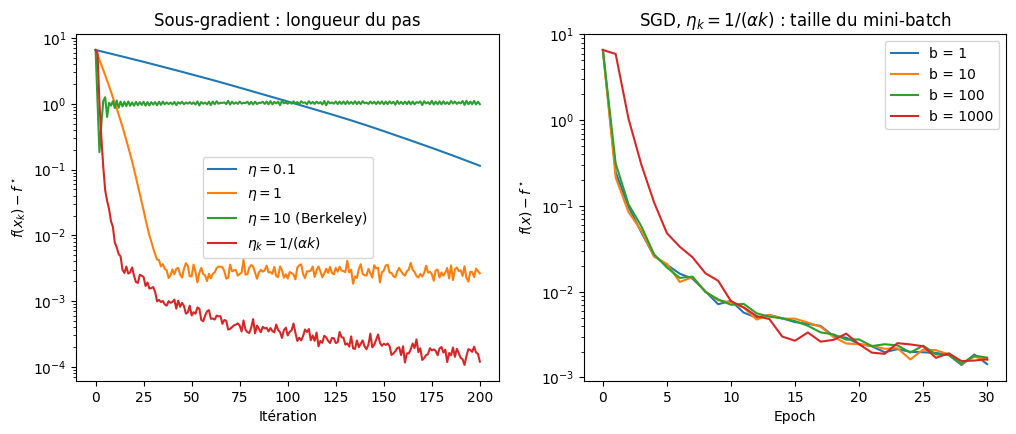

In [12]:
grad = lambda x: svm_subgradient(A, y, x, alpha)
f_ref = svm_objective(A, y, gradient_descent(x0, [1 / (alpha * k) for k in range(1, 20001)], grad)[-1])
f = lambda x: svm_objective(A, y, x) - f_ref + 1e-6   # écart à l'optimum (approché)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for lab, steps in [('$\\eta=0.1$', [0.1] * 200), ('$\\eta=1$', [1.] * 200), ('$\\eta=10$ (Berkeley)', [10.] * 200),
                   ('$\\eta_k=1/(\\alpha k)$', [1 / (alpha * k) for k in range(1, 201)])]:
    ax[0].plot([f(x) for x in gradient_descent(x0, steps, grad)], label=lab)
ax[0].set(yscale='log', xlabel='Itération', ylabel='$f(x_k)-f^\\star$', title='Sous-gradient : longueur du pas'); ax[0].legend()
for b in [1, 10, 100, m]:
    xs_b = sgd(A, y, x0, lambda k: 1 / (alpha * k), batch_size=b, epochs=30)
    ax[1].plot([f(x) for x in xs_b], label=f'b = {b}')
ax[1].set(yscale='log', xlabel='Epoch', ylabel='$f(x)-f^\\star$', title='SGD, $\\eta_k=1/(\\alpha k)$ : taille du mini-batch'); ax[1].legend()
save('pas_minilot'); plt.show()

* **Pas** : un pas constant trop petit est lent, un pas trop grand oscille autour de l'optimum sans converger (pas de
  lissité : le sous-gradient ne s'annule pas près de l'optimum). Le pas décroissant $1/(\alpha k)$ converge, en
  $O(\log k/k)$.
* **Mini-batch** : par epoch, les courbes sont proches. Les petits mini-batchs font $m/b$ fois plus de mises à jour, mais avec
  un sous-gradient plus bruité (variance $\propto1/b$) et des pas $1/(\alpha k)$ qui décroissent d'autant plus vite.
  Par mise à jour, les grands mini-batchs sont donc bien plus efficaces ; le choix de $b$ dépend surtout du coût de calcul
  (vectorisation) et du bruit acceptable.

## 3. Les 6 vérifications de Leung, adaptées au SVM

Le SVM n'est pas un modèle probabiliste : pas de vraisemblance, donc pas de $p$-valeurs de Wald ni de distance de
Cook. On adapte chaque vérification :

| Hypothèse (Leung) | Adaptation au SVM |
|---|---|
| 1. Réponse binaire | réponse codée $\pm1$ |
| 2. Linéarité du logit (Box-Tidwell) | pas de $p$-valeur : on compare la **précision en validation croisée** avec et sans le terme $x\ln x$ (non-linéarité si gain > 1 point) |
| 3. Pas d'observations influentes | seuls les **vecteurs de support** ($y_if(a_i)\le1$) déterminent $\hat x$ ; on compte aussi les points mal classés ($y_if(a_i)<0$) ; histogramme des marges |
| 4. Pas de multicolinéarité | VIF (inchangé, ne dépend que de $X$) |
| 5. Indépendance | autocorrélation des marges $y_if(a_i)$ selon l'ordre des observations (bande $\pm1{,}96/\sqrt m$) |
| 6. Taille suffisante | $m$, effectif de la classe rare par variable, nombre de vecteurs de support |

Le SVM est ajusté sur variables standardisées (avec intercept) par sous-gradient, avec
$\eta_k=1/(\alpha k)$ et $\alpha=0{,}01$.

In [13]:
def fit_svm(X, y, alpha=0.01, iters=5000):
    Z = (X - X.mean(0)) / X.std(0)
    A = np.column_stack([np.ones(len(Z)), Z]); x = np.zeros(A.shape[1])
    for k in range(1, iters + 1):
        x = x - svm_subgradient(A, y, x, alpha) / (alpha * k)
    return A, x

def cv_accuracy(X, y, folds=5, seed=0):
    # précision moyenne en validation croisée (standardisation estimée sur chaque pli d'apprentissage)
    idx = np.random.default_rng(seed).permutation(len(y)); accs = []
    for te in np.array_split(idx, folds):
        tr = np.setdiff1d(idx, te); mu, sd = X[tr].mean(0), X[tr].std(0)
        _, x = fit_svm(X[tr], y[tr], iters=3000)
        accs.append(accuracy(np.column_stack([np.ones(len(te)), (X[te] - mu) / sd]), y[te], x))
    return np.mean(accs)

def check_assumptions_svm(X, y01, continuous, name, tag):
    X = X.astype(float); y = 2 * np.asarray(y01, float) - 1; names = list(X.columns)
    A, x = fit_svm(X.values, y)
    marg = y * (A @ x)
    print(f'===== {name} : m = {len(y)}, {len(names)} variables, précision (apprentissage) = {np.mean(marg > 0):.3f}')
    print(pd.Series(x, index=['const'] + names).round(3).to_string(), '\n')

    # 1. Réponse binaire
    print('1) Modalités de la réponse :', dict(pd.Series(y).value_counts()))

    # 2. Linéarité : précision en validation croisée avec / sans le terme x ln x (Box-Tidwell adapté)
    keep = (X[continuous] > 0).all(axis=1).values
    base = cv_accuracy(X.values[keep], y[keep])
    print(f'2) Box-Tidwell adapté : précision VC (5 plis) du modèle de base = {base:.3f}')
    for c in continuous:
        Xa = X[keep].copy(); Xa[f'{c}:log_{c}'] = Xa[c] * np.log(Xa[c])
        acc = cv_accuracy(Xa.values, y[keep])
        print(f'   + {c} ln {c} : {acc:.3f} (gain {100 * (acc - base):+.1f} pt) ->',
              'non-linéarité' if acc - base > 0.01 else 'linéarité OK')

    # 3. Vecteurs de support et points aberrants
    sv = marg <= 1 + 1e-9
    print(f'3) vecteurs de support (y f <= 1) : {100 * sv.mean():.1f} % ; dont mal classés (y f < 0) : {100 * np.mean(marg < 0):.1f} %')
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].hist(marg, bins=60)
    for v, c in [(-1, 'r'), (0, 'k'), (1, 'g')]:
        ax[0].axvline(v, color=c, ls='--')
    ax[0].set(title='Histogramme des marges $y_i f(a_i)$', xlabel='marge (< 0 : mal classé ; <= 1 : vecteur de support)')

    # 4. VIF
    vif = np.diag(np.linalg.inv(np.corrcoef(X.values, rowvar=False)))
    print('4) VIF :', dict(zip(names, vif.round(2))))

    # 5. Indépendance : autocorrélation des marges selon l'ordre des observations
    r = marg - marg.mean(); lags = np.arange(1, 31)
    acf = np.array([r[:-h] @ r[h:] for h in lags]) / (r @ r)
    band = 1.96 / np.sqrt(len(r))
    ax[1].bar(lags, acf); ax[1].axhline(band, color='r', ls='--'); ax[1].axhline(-band, color='r', ls='--')
    ax[1].set(title='Autocorrélation des marges', xlabel='Décalage'); plt.tight_layout(); save('diag_' + tag); plt.show()
    print(f'5) autocorrélations hors de la bande ±1,96/√m : {np.sum(np.abs(acf) > band)}/30 (≈ 1,5 attendu sous indépendance)')

    # 6. Taille d'échantillon
    epv = min((y > 0).sum(), (y < 0).sum()) / len(names)
    print(f'6) m = {len(y)} ; classe rare par variable = {epv:.1f} (règle : >= 10) ; vecteurs de support = {sv.sum()}')

### 3.1 Titanic (prétraitement de Leung)

===== Titanic : m = 891, 8 variables, précision (apprentissage) = 0.787
const         -0.296
Age           -0.002
Fare           0.001
TravelAlone    0.000
Pclass_2       0.000
Pclass_3      -0.007
Embarked_Q    -0.002
Embarked_S     0.001
Sex_male      -0.957 

1) Modalités de la réponse : {-1.0: 549, 1.0: 342}
2) Box-Tidwell adapté : précision VC (5 plis) du modèle de base = 0.784
   + Age ln Age : 0.784 (gain +0.0 pt) -> linéarité OK
   + Fare ln Fare : 0.784 (gain +0.0 pt) -> linéarité OK
3) vecteurs de support (y f <= 1) : 47.8 % ; dont mal classés (y f < 0) : 21.3 %
4) VIF : {'Age': 1.21, 'Fare': 1.69, 'TravelAlone': 1.22, 'Pclass_2': 2.07, 'Pclass_3': 2.7, 'Embarked_Q': 1.49, 'Embarked_S': 1.48, 'Sex_male': 1.15}


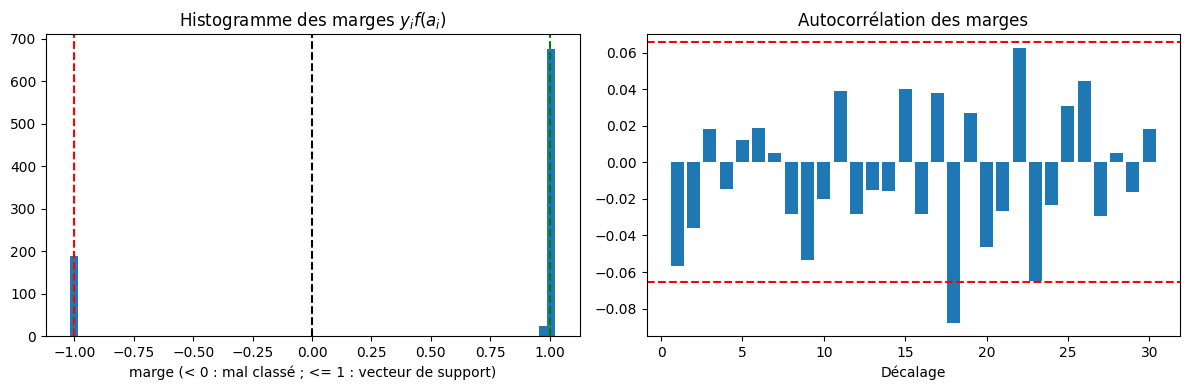

5) autocorrélations hors de la bande ±1,96/√m : 1/30 (≈ 1,5 attendu sous indépendance)
6) m = 891 ; classe rare par variable = 42.8 (règle : >= 10) ; vecteurs de support = 426


In [14]:
df = pd.read_csv('../Kenneth-Leung/data/train.csv')
df['TravelAlone'] = np.where(df.SibSp + df.Parch > 0, 0, 1)
df = df.drop(columns=['SibSp', 'Parch', 'PassengerId', 'Name', 'Ticket', 'Cabin'])
df = pd.get_dummies(df, columns=['Pclass', 'Embarked', 'Sex'], drop_first=True, dtype=float)
df['Age'] = df['Age'].fillna(df['Age'].median())
check_assumptions_svm(df.drop(columns='Survived'), df['Survived'].values, ['Age', 'Fare'], 'Titanic', 'titanic')

Sur Titanic, la solution SVM ne retient pratiquement que le sexe (règle « les femmes survivent », précision 0,787).
Conséquence : $f(a_i)\approx\pm1$ pour tous les passagers, donc les marges valent presque exactement $+1$ (bien
classé) ou $-1$ (mal classé), ce qui explique l'histogramme à deux pics. Ce n'est pas un défaut de convergence : la perte charnière est linéaire par morceaux et l'optimum se trouve en un
« sommet » où la plupart des coefficients sont nuls. Vérification avec scikit-learn (même objectif, $C=1/(\alpha m)$) :

In [15]:
from sklearn.svm import LinearSVC
Xt = df.drop(columns='Survived').values.astype(float); yt = 2 * df['Survived'].values - 1.
At, xt = fit_svm(Xt, yt)
sk = LinearSVC(C=1 / (0.01 * len(yt)), loss='hinge', fit_intercept=False, max_iter=100000).fit(At, yt)
print('notre GD     :', xt.round(3), f'objectif = {svm_objective(At, yt, xt, 0.01):.4f}')
print('scikit-learn :', sk.coef_.ravel().round(3), f'objectif = {svm_objective(At, yt, sk.coef_.ravel(), 0.01):.4f}')

notre GD     : [-0.296 -0.002  0.001  0.     0.    -0.007 -0.002  0.001 -0.957] objectif = 0.4327
scikit-learn : [-0.295  0.     0.     0.     0.     0.    -0.    -0.    -0.955] objectif = 0.4315


### 3.2 Irish Educational Transitions ([OpenML 451](https://www.openml.org/d/451))
Même prétraitement qu'au projet 1 : on retire les élèves sortis après le primaire, `Educational_level` et les
valeurs manquantes.

===== Irish Educational Transitions : m = 441, 4 variables, précision (apprentissage) = 0.741
const                     0.408
DVRT                      0.002
Prestige_score            0.001
Sex_male                  0.000
Type_school_vocational   -0.911 

1) Modalités de la réponse : {-1.0: 230, 1.0: 211}
2) Box-Tidwell adapté : précision VC (5 plis) du modèle de base = 0.742
   + DVRT ln DVRT : 0.742 (gain +0.0 pt) -> linéarité OK
   + Prestige_score ln Prestige_score : 0.742 (gain +0.0 pt) -> linéarité OK
3) vecteurs de support (y f <= 1) : 62.6 % ; dont mal classés (y f < 0) : 25.9 %
4) VIF : {'DVRT': 1.17, 'Prestige_score': 1.12, 'Sex_male': 1.09, 'Type_school_vocational': 1.24}


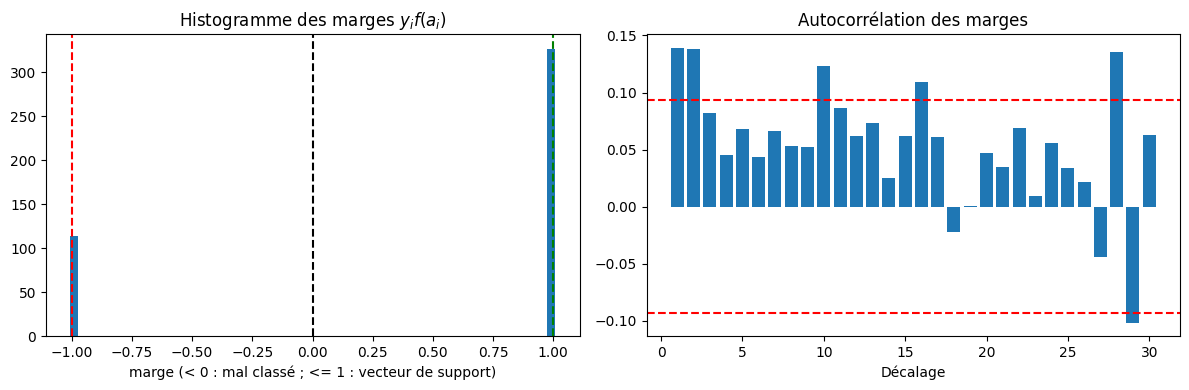

5) autocorrélations hors de la bande ±1,96/√m : 6/30 (≈ 1,5 attendu sous indépendance)
6) m = 441 ; classe rare par variable = 52.8 (règle : >= 10) ; vecteurs de support = 276


In [16]:
from sklearn.datasets import fetch_openml
if os.path.exists('data/irish.csv'):
    ir = pd.read_csv('data/irish.csv')
else:
    ir = fetch_openml(data_id=451, as_frame=True).frame
    os.makedirs('data', exist_ok=True); ir.to_csv('data/irish.csv', index=False)
ir = ir.astype({c: str for c in ['Sex', 'Type_school', 'Leaving_Certificate']})
ir = ir[ir.Type_school != 'primary_terminal_leaver'].drop(columns='Educational_level').dropna()
y_ir = (ir.pop('Leaving_Certificate') == 'taken').values
X_ir = pd.get_dummies(ir, columns=['Sex', 'Type_school'], drop_first=True, dtype=float)
check_assumptions_svm(X_ir, y_ir, ['DVRT', 'Prestige_score'], 'Irish Educational Transitions', 'irlande')

## Conclusion
* Le sous-gradient avec un pas constant stagne à une distance de l'optimum proportionnelle au pas ($\eta=10$, pas de Berkeley, oscille) ; seul le pas décroissant $1/(\alpha k)$ continue de progresser.
* Mini-batch : par epoch, les tailles de $b=1$ à $b=1000$ donnent des courbes proches ; par mise à jour, les grands mini-batchs sont plus efficaces.
* Sur Titanic et sur les données irlandaises, la solution SVM ne garde qu'une variable (le sexe, puis le type d'école) : c'est l'optimum de la perte charnière, confirmé par scikit-learn, et non un problème de convergence.
* Vérifications de Leung adaptées : pas de non-linéarité détectée, VIF faibles, effectifs suffisants. Sur les données irlandaises, 6 autocorrélations sur 30 sortent de la bande, car les élèves sont regroupés dans le fichier (la réponse elle-même est autocorrélée selon l'ordre des lignes).